# EEI-303 – Processamento de Voz e Áudio

## 24202631372 - Matheus Costa Damasceno

---

# Aula 12 - Laboratório 4 - Codificação de áudio por banco de filtros

O material desta aula foi adaptado de:

1. Dutoit, T. and Moreau, N. How is sound processed in an MP3 player?, In: Applied Signal Processing, Edited by Duotit, T. and Narques, F., Chapter 3, Springer, 2009

2. HWANG, J., Multimedia networking: From Theory to Practice, Cambridge, 2009.

3. https://github.com/GuitarsAI/AudioCodingTutorials/blob/master/AC_03_FilterBanks2.ipynb

As atividades deverão ser realizadas no ambiente COLAB ou em Jupyter Notebook e o arquivo, contendo os resultados e as respostas das questões, enviado em formato .ipynb pelo formulário.

In [1]:
import scipy.signal as signal
import numpy as np
import scipy
import matplotlib.pyplot as plt
import librosa
import math
from pylab import *
from IPython.display import Audio
from librosa.display import specshow

In [2]:
import os, urllib.request

REPO_RAW = "https://raw.githubusercontent.com/Mathcd/2026-3-Processamento-de-Voz-e-Audio/main/2-ExerciciosComputacionais/Audios/"

def caminho_audio(nome):
    """Usa o áudio local se existir; senão baixa do GitHub (ex.: no Colab)."""
    caminho = os.path.join("Audios", nome)
    if not os.path.exists(caminho):
        os.makedirs("Audios", exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + nome, caminho)
    return caminho

In [3]:
#@title
# Downsampling
def decimate(x, q):
    # Downsample the signal
    sl = [slice(None)] * x.ndim
    sl = slice(None, None, q)

    return x[sl]

# Upsampling
def upsample(x, p):
    # upsample the signal
    ylen = p*len(x)
    y    = np.zeros(ylen)
    sl = [slice(None)] * y.ndim
    sl = slice(None, None, p)
    y[sl] = x
    return y

# Quantization
def quantize(x, S):
    X = x.reshape((-1,1))
    S = S.reshape((1,-1))
    dists = abs(X-S)

    nearestIndex = dists.argmin(axis=1)
    quantized = S.flat[nearestIndex]

    return quantized.reshape(x.shape)

#Plot frequency and phase response - adaptado de http://mpastell.com/pweave/_downloads/FIR_design_rst.html
def mfreqz(b,a=1):
    w,h = signal.freqz(b,a)
    h_dB = 20 * np.log10 (abs(h))
    plt.figure(figsize=(12,6))
    subplot(211)
    plot(w/max(w),h_dB)
    ylabel('Amplitude [dB]')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Frequency response')
    plt.grid(True)
    subplot(212)
    h_Phase = unwrap(arctan2(imag(h),real(h)))
    plot(w/max(w),h_Phase)
    ylabel('Phase (radians)')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Phase response')
    subplots_adjust(hspace=0.5)
    plt.grid(True)

#Plot inpulse response, frequency, phase response and delay group - adaptado de http://mpastell.com/pweave/_downloads/FIR_design_rst.html
def mfreqz2(b,a=1):
    w,h = signal.freqz(b,a)
    end = len(h)
    h_dB = 20 * np.log10 (abs(h))
    plt.figure(figsize=(12,12))
    subplot(311)
    stem(b)
    ylabel('Amplitude')
    xlabel(r'Samples')
    title(r'Impulse response')
    plt.grid(True)
    subplot(312)
    plot(w/max(w),h_dB)
    ylim(-150, 1.1*max(h_dB))
    ylabel('Amplitude [dB]')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Frequency response')
    plt.grid(True)
    subplot(313)
    h_Phase = unwrap(arctan2(imag(h),real(h)))
    plot(w/max(w),h_Phase)
    ylabel('Phase (radians)')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Phase response')
    subplots_adjust(hspace=0.5)
    plt.grid(True)


In [4]:
from IPython.display import display

def quantize_midtread(x, U, b):
    """Quantizador mid-tread uniforme com 2**b níveis em [-U, U - Delta].
    Equivale a quantize(x, S_midtread), mas sem montar a matriz de distâncias
    (que, com 12 bits, ocupa ~1,5 GB por banda)."""
    LL    = 2**b
    Delta = 2*U/LL
    idx   = np.clip(np.floor((x + U)/Delta + 0.5), 0, LL - 1)
    return -U + idx*Delta


def codificar(s, b, U_modo='fixo', U_fixo=3.8, bits_original=12, titulo='',
              plot_bandas=False, mostrar=True):
    """Codificador/decodificador por subbandas com o banco de filtros MDCT (H, G, q).

    s             : sinal de entrada
    b             : vetor com o número de bits de cada uma das q bandas (0 = banda descartada)
    U_modo        : 'fixo' -> U = U_fixo em todas as bandas
                    'max'  -> U = max(abs(s_dec)) de cada banda
    bits_original : resolução assumida para o arquivo original (cálculo da compressão)
    plot_bandas   : True gera a figura com as 32 bandas (deixa o notebook bem maior)
    mostrar       : True exibe tabela, gráficos, áudio e espectrogramas
    """
    s  = np.copy(s)
    L  = len(s)
    y  = np.zeros(L)
    largura = fs/(2*q)                       # largura de cada banda (750 Hz)

    U_bandas   = np.zeros(q)
    snr_bandas = np.zeros(q)
    max_bandas = np.zeros(q)

    if plot_bandas:
        fig, axes = plt.subplots(8, 4, figsize=(20, 30))
        axes = axes.flatten()

    for ii in range(q):
        s_dec = decimate(np.convolve(H[ii,:], s, 'same'), q)
        Lq    = len(s_dec)
        max_bandas[ii] = max(abs(s_dec))

        if b[ii] == 0:
            sq   = np.zeros(Lq)
            s_up = np.zeros(L)
        else:
            U    = U_fixo if U_modo == 'fixo' else max_bandas[ii]
            U_bandas[ii] = U
            sq   = quantize_midtread(s_dec, U, b[ii])
            s_up = upsample(sq, q)

        y = y + np.convolve(G[ii,:], s_up, 'same')

        erro_banda = s_dec - sq
        p_sinal, p_ruido = np.sum(s_dec**2), np.sum(erro_banda**2)
        snr_bandas[ii] = 10*np.log10(p_sinal/p_ruido) if p_ruido > 0 else np.inf

        if plot_bandas:
            t_dec = np.arange(Lq)*(q/fs)
            ax = axes[ii]
            ax.plot(t_dec, s_dec, label='Sinal decimado')
            ax.plot(t_dec, sq, label='Sinal decimado e quantizado')
            ax.plot(t_dec, erro_banda, label='Erro da banda', linestyle='--')
            ax.legend(loc='upper right', shadow=True, fontsize='x-small')
            ax.set_xlabel('Tempo (s)')
            ax.set_ylabel('Amplitude')
            ax.set_title(f'Banda {ii+1} ({b[ii]} bits)')
            ax.grid(True)
            ax.set_xlim([10, 10.50])

    if plot_bandas:
        plt.suptitle(f'Sinais decimados, quantizados e erro por banda - {titulo}', fontsize=16)
        plt.tight_layout(rect=[0, 0.03, 1, 0.98])
        plt.show()

    # Alinhamento de 1 amostra entre entrada e saída (como no código original)
    yd = np.copy(y)
    yd[0:L-1] = y[1:L]
    ey = s - yd

    snr_total = 10*np.log10(np.sum(s**2)/np.sum(ey**2))

    # Tamanhos e taxa de compressão
    bits_orig = L*bits_original
    bits_comp = Lq*np.sum(b)
    taxa      = bits_orig/bits_comp

    if mostrar:
        print(f'===== {titulo} | U = {U_modo}' + (f' ({U_fixo})' if U_modo == 'fixo' else ''))
        print(f'{"Banda":>5} | {"Faixa [Hz]":>13} | {"Bits":>4} | {"max|s_dec|":>10} | {"U":>7} | {"SNR [dB]":>8}')
        for ii in range(q):
            faixa = f'{ii*largura:.0f}-{(ii+1)*largura:.0f}'
            snr   = '-' if b[ii] == 0 else f'{snr_bandas[ii]:.2f}'
            U_txt = '-' if b[ii] == 0 else f'{U_bandas[ii]:.4f}'
            print(f'{ii+1:>5} | {faixa:>13} | {b[ii]:>4} | {max_bandas[ii]:>10.4f} | {U_txt:>7} | {snr:>8}')
        print(f'\nSNR total: {snr_total:.2f} dB')
        print(f'Tamanho original ({bits_original} bits/amostra): {bits_orig} bits ({bits_orig/8/1024**2:.2f} MB)')
        print(f'Tamanho comprimido (soma de b = {np.sum(b)} bits a cada {q} amostras): {bits_comp} bits ({bits_comp/8/1024**2:.2f} MB)')
        print(f'Taxa de compressão: {taxa:.2f}')

        # Sinal original x sintetizado e erro (50 ms)
        t = np.arange(L)/fs
        plt.figure(figsize=(12,6))
        plt.subplot(2,1,1)
        plt.plot(t, s, label='Sinal original')
        plt.plot(t, yd, label='Sinal sintetizado')
        plt.legend(loc='upper center', shadow=True, fontsize='x-large')
        plt.title(titulo)
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.xlim([10, 10.050])
        plt.subplot(2,1,2)
        plt.plot(t, ey)
        plt.xlabel('Tempo (s)')
        plt.ylabel('Erro de sintetização')
        plt.grid(True)
        plt.xlim([10, 10.050])
        plt.show()

        print('Áudio codificado/decodificado:')
        display(Audio(data=yd, rate=fs))

        # Espectrogramas
        plt.figure(figsize=(18,6))
        for i, (sinal, nome) in enumerate([(s, 'Original'), (yd, 'Codificado/Decodificado'), (ey, 'Erro')]):
            plt.subplot(1,3,i+1)
            specshow(librosa.amplitude_to_db(np.abs(librosa.stft(sinal))),
                     y_axis='log',
                     x_axis='time',
                     cmap='jet',
                     sr=fs)
            plt.title(f'{nome} - {titulo}')
            plt.xlabel('Time [s]')
            plt.ylabel('Frequency [Hz]')
            plt.clim(-45, 45)
            plt.colorbar(format='%+2.0f dB')
        plt.tight_layout()
        plt.show()

    return {'y': yd, 'erro': ey, 'snr_total': snr_total, 'snr_bandas': snr_bandas,
            'U_bandas': U_bandas, 'bits_comprimido': bits_comp, 'taxa': taxa}


/tmp/ipykernel_2884690/2702377541.py:34: RuntimeWarning: divide by zero encountered in log10
  h_dB = 20 * np.log10 (abs(h))


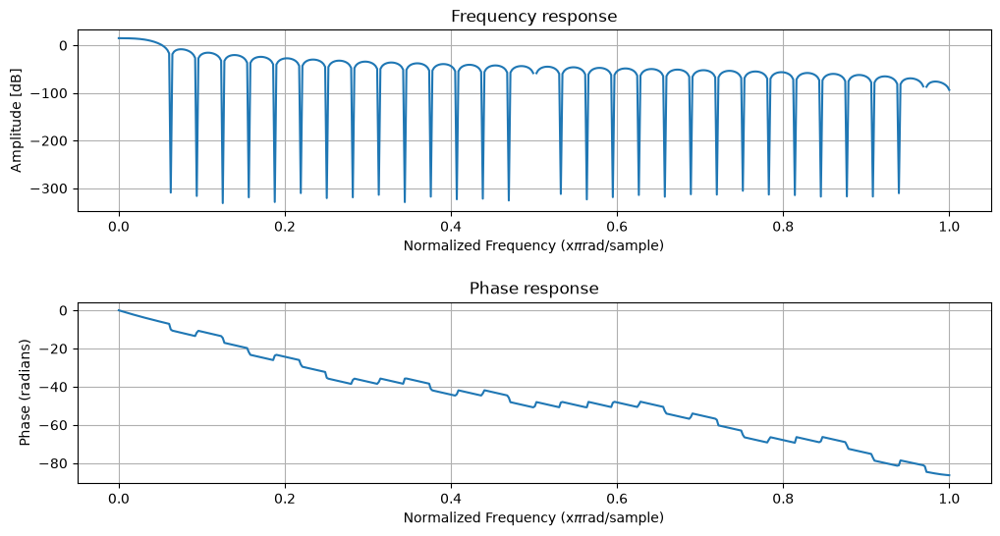

In [5]:
q = 32
n = arange(2*q)
H = np.zeros([q,2*q])
G = np.zeros([q,2*q])
h = sin((n+0.5)*pi/(2*q))
for ii in range(q):
  fi   = (2*ii+1)/(4*q)
  phii = ((2*ii+1)*(-q+1)*pi)/(4*q)
  G[ii,:] = h*sqrt(2/q)*cos(2*pi*fi*n+phii)
  for jj in range(2*q):
    H[ii,jj] = np.copy(G[ii,2*q-1-jj])

mfreqz(H[0,:],a=1)


Faça o download do arquivo "audio3-crop.wav", disponível em: https://drive.google.com/drive/folders/1hv1v7FDmGPNS1Mvhh7kY1b9ZCJ-t697G?usp=drive_link

https://audio.com/michael-janovic/audio/true-hi-res-audio-flac-lossless-sound-test-experience

In [6]:
audio_sample, fs = librosa.load(caminho_audio("audio4_cut.wav"), sr=48000) # 48000 corresponde à taxa de amostragem do sinal

## Exercício 1

Com o auxílio deste COLAB iremos programar um codificador e decodificador por subbandas utilizando um banco de filtros MDCT de 32 bandas. Para saber quantos bits utilizar na requantização, para cada banda, iremos nos basear no esquema proposto na Figura 1. Observe que esta figura apresenta um esquema para 12 bandas apenas, dividida de 0 a 15kHz e o esquema proposto são de 32 bandas de 0 a 24kHz (Taxa de amostragem igual a 48kHz). Desta forma, será necessário adaptar o esquema da figura para o banco de filtros proposto.

<center>
  <img src="https://drive.google.com/uc?id=1iR5toFOBTp9gGK1a0c1tqL8DvZL5bVXo"
	width="65%" />
</center>

Figura 1. Número de bits utilizado na requantização baseado na curva de **sensibilidade auditiva**. Figura extraída de: HWANG, J., Multimedia networking: From Theory to Practice, Cambridge, 2009.

1. Monte uma tabela indicando os intervalos de frequência de cada filtro com o respectivo número de bits utilizado na quantização;

Tabela proposta para a requantização do Exercício 1

Banda   | $f_i$ [Hz] | $f_u$ [Hz] | Nº de bits
------ | ---------- | ---------- | ---------------
1  |    0 |  750 | 12
2  |  750 | 1500 | 12
3  | 1500 | 2250 | 12
4  | 2250 | 3000 | 12
5  | 3000 | 3750 | 12
6  | 3750 | 4500 | 12
7  | 4500 | 5250 | 12
8  | 5250 | 6000 | 11
9  | 6000 | 6750 | 11
10 | 6750 | 7500 | 10
11 | 7500 | 8250 | 10
12 | 8250 | 9000 | 9
13 | 9000 | 9750 | 9
14 | 9750 | 10500 | 9
15 | 10500 | 11250 | 10
16 | 11250 | 12000 | 10
17 | 12000 | 12750 | 10
18 | 12750 | 13500 | 10
19 | 13500 | 14250 | 10
20 | 14250 | 15000 | 9
21 | 15000 | 15750 | 9
22 | 15750 | 16500 | 9
23 | 16500 | 17250 | 9
24 | 17250 | 18000 | 9
25 | 18000 | 18750 | 8
26 | 18750 | 19500 | 8
27 | 19500 | 20250 | 8
28 | 20250 | 21000 | 8
29 | 21000 | 21750 | 8
30 | 21750 | 22500 | 8
31 | 22500 | 23250 | 8
32 | 23250 | 24000 | 8

In [7]:
# Número de bits alocado por subbanda de frequência
b1 = np.array([12, 12, 12, 12, 12, 12, 12, 11, 11, 10, 10, 9, 9, 9, 10, 10, 10, 10, 10, 9, 9, 9, 9, 9, 8, 8, 8, 8, 8, 8, 8, 8])
assert len(b1) == 32

# Codificação/Decodificação por subbanda

In [8]:
Audio(data=audio_sample, rate=fs) # audio original

---

2. Qual o tamanho do arquivo original (tendo como base que o mesmo foi quantizado originalmente com 16 bits) e qual o tamanho do arquivo comprimido? Qual a taxa de compressão obtida?

- Tamanho original: 23040000 bits (2.75 MB)
- Tamanho comprimido: 14040000 bits (1.67 MB)
- Taxa de compressão: 1.64

---

3. Realize a codificação e decodificação (Na quantização, utilize "U = 3.8") do sinal de áudio fornecido e verifique se houve diferenças significativas na compressão (tanto na escuta quanto nos espectrogramas);

===== Ex. 1 - U = 3,8 | U = fixo (3.8)
Banda |    Faixa [Hz] | Bits | max|s_dec| |       U | SNR [dB]
    1 |         0-750 |   12 |     3.0108 |  3.8000 |    65.14
    2 |      750-1500 |   12 |     2.5838 |  3.8000 |    60.32
    3 |     1500-2250 |   12 |     1.6099 |  3.8000 |    56.65
    4 |     2250-3000 |   12 |     1.3459 |  3.8000 |    53.38
    5 |     3000-3750 |   12 |     1.1661 |  3.8000 |    53.00
    6 |     3750-4500 |   12 |     1.1383 |  3.8000 |    51.16
    7 |     4500-5250 |   12 |     0.9708 |  3.8000 |    49.71
    8 |     5250-6000 |   11 |     1.0205 |  3.8000 |    38.46
    9 |     6000-6750 |   11 |     0.6925 |  3.8000 |    36.24
   10 |     6750-7500 |   10 |     0.6703 |  3.8000 |    30.41
   11 |     7500-8250 |   10 |     0.5894 |  3.8000 |    29.63
   12 |     8250-9000 |    9 |     0.5183 |  3.8000 |    22.85
   13 |     9000-9750 |    9 |     0.5077 |  3.8000 |    22.00
   14 |    9750-10500 |    9 |     0.4042 |  3.8000 |    21.33
   15 |   10500-

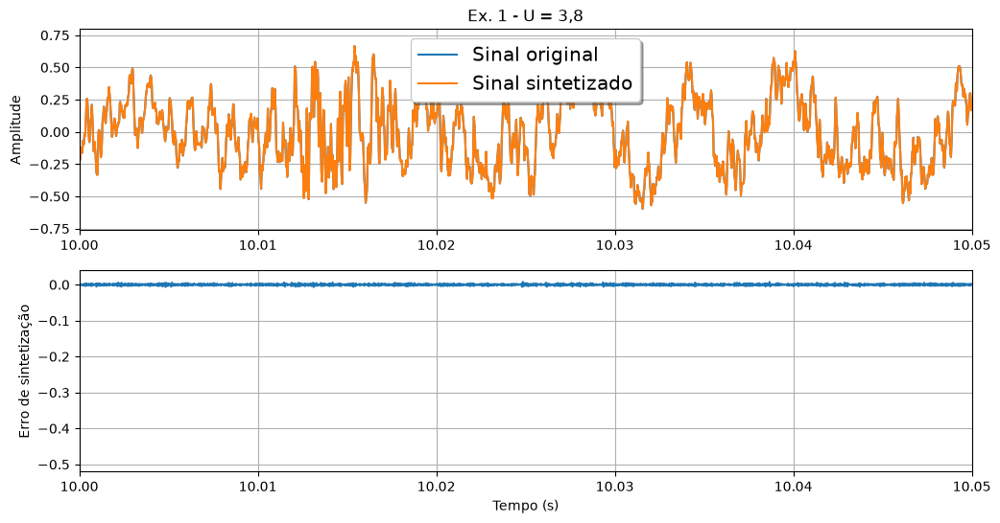

Áudio codificado/decodificado:


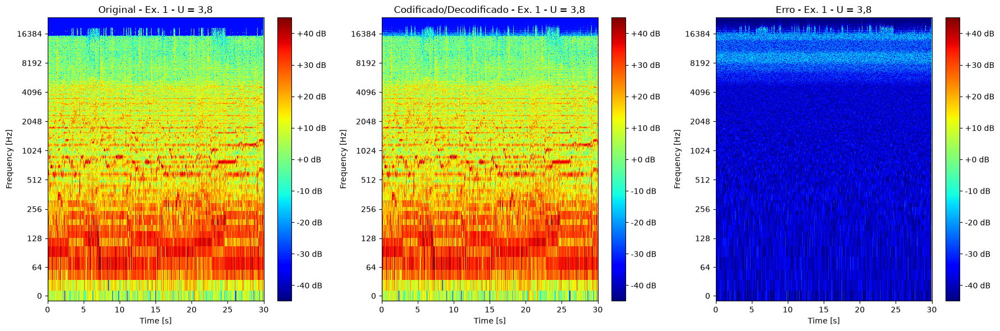

In [9]:
# Exercício 1 - item 3: U = 3.8
r1_fixo = codificar(audio_sample, b1, bits_original=16, U_modo='fixo', titulo='Ex. 1 - U = 3,8')

Perceptualmente, não foi possível identificar uma diferença clara entre o áudio original e o áudio comprimido ao escutá-los. Porém, observando o espectrograma, verifica-se que o erro é maior nas faixas de alta frequência, especialmente entre 8.000 e 16.500 Hz.

---

4. Realize a codificação e decodificação (Na quantização, utilize "U = max(abs(s_dec))") do sinal de áudio fornecido e verifique se houve diferenças significativas na compressão (tanto na escuta quanto nos espectrogramas);

===== Ex. 1 - U = max(abs(s_dec)) | U = max
Banda |    Faixa [Hz] | Bits | max|s_dec| |       U | SNR [dB]
    1 |         0-750 |   12 |     3.0108 |  3.0108 |    67.18
    2 |      750-1500 |   12 |     2.5838 |  2.5838 |    63.67
    3 |     1500-2250 |   12 |     1.6099 |  1.6099 |    64.11
    4 |     2250-3000 |   12 |     1.3459 |  1.3459 |    62.35
    5 |     3000-3750 |   12 |     1.1661 |  1.1661 |    63.26
    6 |     3750-4500 |   12 |     1.1383 |  1.1383 |    61.64
    7 |     4500-5250 |   12 |     0.9708 |  0.9708 |    61.57
    8 |     5250-6000 |   11 |     1.0205 |  1.0205 |    49.85
    9 |     6000-6750 |   11 |     0.6925 |  0.6925 |    51.06
   10 |     6750-7500 |   10 |     0.6703 |  0.6703 |    45.46
   11 |     7500-8250 |   10 |     0.5894 |  0.5894 |    45.84
   12 |     8250-9000 |    9 |     0.5183 |  0.5183 |    40.15
   13 |     9000-9750 |    9 |     0.5077 |  0.5077 |    39.48
   14 |    9750-10500 |    9 |     0.4042 |  0.4042 |    40.84
   15 |   1

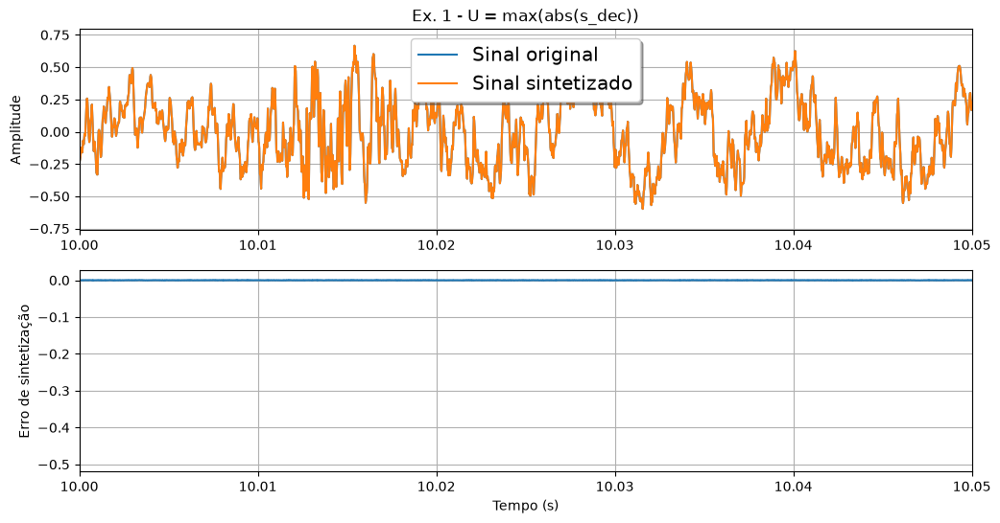

Áudio codificado/decodificado:


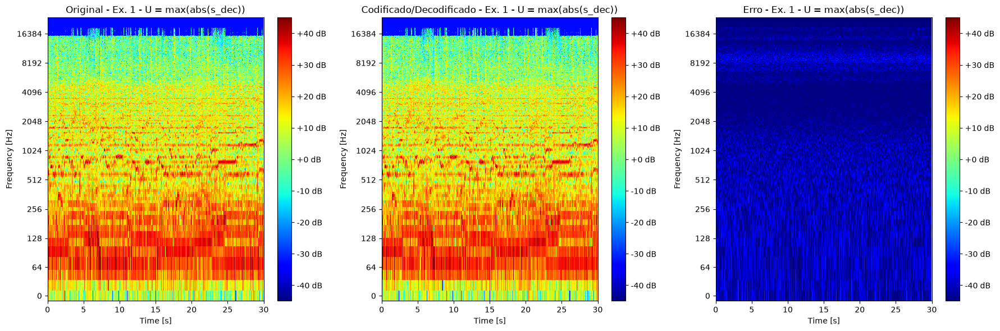

In [10]:
# Exercício 1 - item 4: U = max(abs(s_dec))
r1_max = codificar(audio_sample, b1, bits_original=16, U_modo='max', titulo='Ex. 1 - U = max(abs(s_dec))')

Assim como no item anterior, também não foi possível perceber uma diferença clara entre os dois áudios. Além disso, utilizando essa estratégia, o erro foi ainda menor, principalmente nas faixas de alta frequência, de modo que o sinal codificado ficou muito próximo do sinal original. Inclusive, observou-se que a SNR foi de aproximadamente 46 dB, enquanto no item anterior foi de apenas 39 dB.

---

5. Compare os itens 3. e 4. Houve diferença significativa entre utilizar um valor constante para U e um valor que se modifica para cada banda?


Sim, porém a diferença não foi observada ao ouvir os áudios, apenas nos espectrogramas e na SNR. No primeiro cenário (U fixo), especialmente nas faixas de alta frequência, houve erro de quantização maior, tendo em vista que essas componetes tendem a ter amplitudes mais baixas, e como a escala do quantizador é fixa, elas são representadas com poucos níveis e sofrem mais com erros de arredondamento. Esse padrão não é observado no item 4, já que a escala do quantizador é ajustada pela amplitude de cada faixa. Além disso, a SNR no item 4 aumentou (de 39 para 46 dB) mantendo a mesma taxa de compressão (1.64).

---

## Exercício 2

<center>

  <img src="https://drive.google.com/uc?id=1VZJyb_5lgMOtYf8uQ-L9ZRjXEKdqBXQj"
	width="65%" />
</center>

Figura 2. Número de bits utilizado na requantização baseado nas curvas de **sensibilidade auditiva** e **mascaramento em frequência**. Figura extraída de: HWANG, J., Multimedia networking: From Theory to Practice, Cambridge, 2009.

1. Proponha agora uma nova tabela tabela indicando os intervalos de frequência de cada filtro com o respectivo número de bits utilizado na quantização com base no modelo Psicoacústico apresentado na Figura 2, que leva em consideração as curvas de sensibilidade auditivo e mascaramento em frequência. Esta nova tabela deverá apresentar uma taxa de compressão maior do que 3.

Tabela proposta para a requantização do Exercício 1

Banda   | $f_i$ [Hz] | $f_u$ [Hz] | Nº de bits
------ | ---------- | ---------- | ---------------
1  |    0 |  750 | 5
2  |  750 | 1500 | 5
3  | 1500 | 2250 | 5
4  | 2250 | 3000 | 5
5  | 3000 | 3750 | 5
6  | 3750 | 4500 | 5
7  | 4500 | 5250 | 5
8  | 5250 | 6000 | 4
9  | 6000 | 6750 | 4
10 | 6750 | 7500 | 4
11 | 7500 | 8250 | 4
12 | 8250 | 9000 | 4
13 | 9000 | 9750 | 3
14 | 9750 | 10500 | 3
15 | 10500 | 11250 | 3
16 | 11250 | 12000 | 3
17 | 12000 | 12750 | 3
18 | 12750 | 13500 | 2
19 | 13500 | 14250 | 2
20 | 14250 | 15000 | 2
21 | 15000 | 15750 | 1
22 | 15750 | 16500 | 1
23 | 16500 | 17250 | 1
24 | 17250 | 18000 | 1
25 | 18000 | 18750 | 1
26 | 18750 | 19500 | 1
27 | 19500 | 20250 | 1
28 | 20250 | 21000 | 1
29 | 21000 | 21750 | 1
30 | 21750 | 22500 | 1
31 | 22500 | 23250 | 1
32 | 23250 | 24000 | 1

In [11]:
# Número de bits alocado por subbanda de frequência
b2 = np.array([5, 5, 5, 5, 5, 5, 5, 4, 4, 4, 4, 4, 3, 3, 3, 3, 3, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])
assert len(b2) == 32

---

2. Qual o tamanho do arquivo original (tendo como base que o mesmo foi quantizado originalmente com 12 bits) e qual o tamanho do arquivo comprimido? Qual a taxa de compressão obtida?

- Tamanho original: 17280000 bits (2.06 MB)
- Tamanho comprimido: 3960000 bits (0.47 MB)
- Taxa de compressão: 4.36

---

3. Realize a codificação e decodificação (Na quantização, utilize "U = 3.8") do sinal de áudio fornecido e verifique se houve diferenças significativas na compressão (tanto na escuta quanto nos espectrogramas);

===== Ex. 2 - U = 3,8 | U = fixo (3.8)
Banda |    Faixa [Hz] | Bits | max|s_dec| |       U | SNR [dB]
    1 |         0-750 |    5 |     3.0108 |  3.8000 |    22.98
    2 |      750-1500 |    5 |     2.5838 |  3.8000 |    18.18
    3 |     1500-2250 |    5 |     1.6099 |  3.8000 |    14.52
    4 |     2250-3000 |    5 |     1.3459 |  3.8000 |    11.19
    5 |     3000-3750 |    5 |     1.1661 |  3.8000 |    10.85
    6 |     3750-4500 |    5 |     1.1383 |  3.8000 |     9.01
    7 |     4500-5250 |    5 |     0.9708 |  3.8000 |     7.57
    8 |     5250-6000 |    4 |     1.0205 |  3.8000 |     0.52
    9 |     6000-6750 |    4 |     0.6925 |  3.8000 |     0.40
   10 |     6750-7500 |    4 |     0.6703 |  3.8000 |     0.35
   11 |     7500-8250 |    4 |     0.5894 |  3.8000 |     0.34
   12 |     8250-9000 |    4 |     0.5183 |  3.8000 |     0.40
   13 |     9000-9750 |    3 |     0.5077 |  3.8000 |     0.00
   14 |    9750-10500 |    3 |     0.4042 |  3.8000 |     0.00
   15 |   10500-

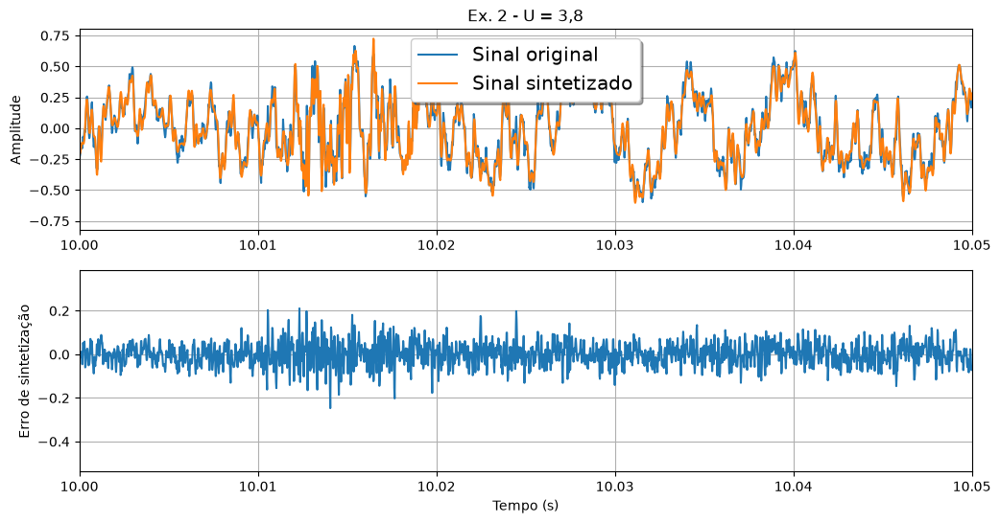

Áudio codificado/decodificado:


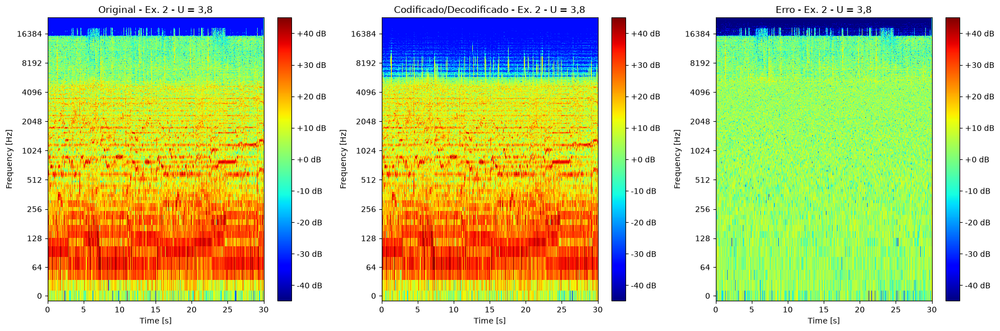

In [12]:
# Exercício 2 - item 3: U = 3.8
r2_fixo = codificar(audio_sample, b2, U_modo='fixo', titulo='Ex. 2 - U = 3,8')

Neste caso, foi possível observa uma diferença significativa não somente no espectrograma e na SNR (13,2 dB), como também perceptualmente. O áudio ficou com uma qualidade muito degradada, causando a impressão similar ao de uma música sendo reproduzida por meio da rede de telefonia. Comparando o espectrograma do erro, verifica-se que praticamente todas as faixas até 16 kHz apresenta erro na ordem de 0 a 10 dB. Outro ponto interessante é que o sinal codificado praticamente perdeu as componentes acima de 5000 Hz, resultado do processo de quantização adotado com escala fixa.

---

4. Realize a codificação e decodificação (Na quantização, utilize "U = max(abs(s_dec))") do sinal de áudio fornecido e verifique se houve diferenças significativas na compressão (tanto na escuta quanto nos espectrogramas quanto na SNR)

===== Ex. 2 - U = max(abs(s_dec)) | U = max
Banda |    Faixa [Hz] | Bits | max|s_dec| |       U | SNR [dB]
    1 |         0-750 |    5 |     3.0108 |  3.0108 |    24.98
    2 |      750-1500 |    5 |     2.5838 |  2.5838 |    21.51
    3 |     1500-2250 |    5 |     1.6099 |  1.6099 |    22.01
    4 |     2250-3000 |    5 |     1.3459 |  1.3459 |    20.20
    5 |     3000-3750 |    5 |     1.1661 |  1.1661 |    21.09
    6 |     3750-4500 |    5 |     1.1383 |  1.1383 |    19.44
    7 |     4500-5250 |    5 |     0.9708 |  0.9708 |    19.38
    8 |     5250-6000 |    4 |     1.0205 |  1.0205 |     7.78
    9 |     6000-6750 |    4 |     0.6925 |  0.6925 |     8.87
   10 |     6750-7500 |    4 |     0.6703 |  0.6703 |     9.36
   11 |     7500-8250 |    4 |     0.5894 |  0.5894 |     9.70
   12 |     8250-9000 |    4 |     0.5183 |  0.5183 |    10.07
   13 |     9000-9750 |    3 |     0.5077 |  0.5077 |     3.96
   14 |    9750-10500 |    3 |     0.4042 |  0.4042 |     5.00
   15 |   1

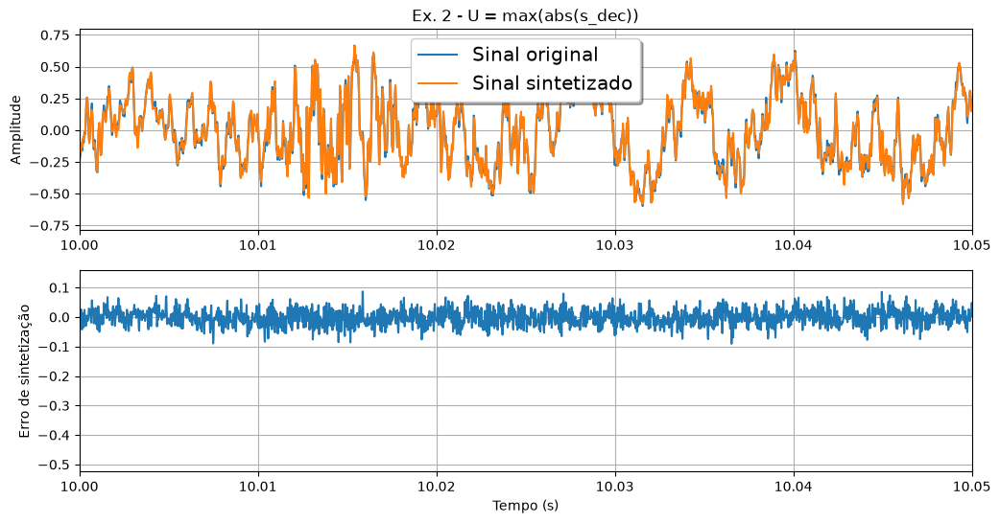

Áudio codificado/decodificado:


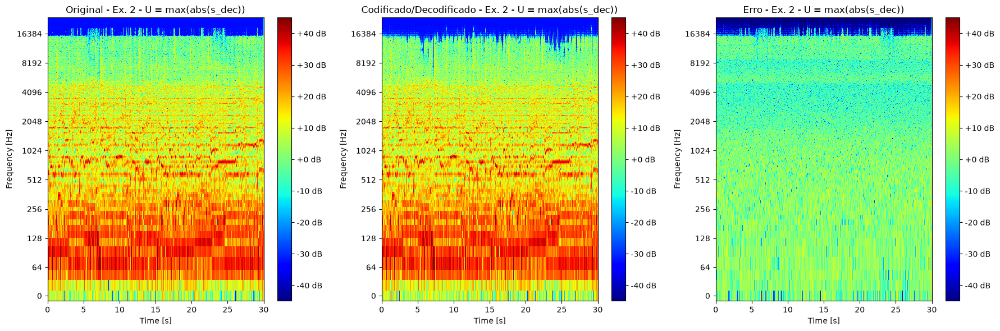

In [13]:
# Exercício 2 - item 4: U = max(abs(s_dec))
r2_max = codificar(audio_sample, b2, U_modo='max', titulo='Ex. 2 - U = max(abs(s_dec))')


Analisando o erro, observa-se que suas componentes são bem maiores do que as vistas no Exercício 1; porém, o erro de quantização é bem menor do que no item 3, justamente por se utilizar uma escala adaptativa, e a SNR aumentou de 13,2 para 18,7 dB. Além disso, as componentes acima de 5 kHz voltam a aparecer no espectrograma do sinal codificado, ainda que com um pouco de distorção. Perceptualmente, o áudio parece estar sendo reproduzido por uma caixa de som que não é de alta fidelidade, sendo possível perceber uma degradação, porém a qualidade é muito superior à observada no item 3.

---

5. Compare os itens 3. e 4. Houve diferença significativa entre utilizar um valor constante para U e um valor que se modifica para cada banda?

Sim, houve uma diferença muito mais acentuada que a observada no exercício 1. Uma vez que foram adotados menos bits para quantizar o áudio, as diferenças entre os erros de quantização nas duas abordagens ficaram ainda mais evidentes e a qualidade do áudio codificado com U fixo ficou muito pior. Nas componentes de alta frequência, que possuem energia menor, praticamente todas as amplitudes acima de 5 kHz foram atenuadas pelo erro de quantização, o que não ocorreu com U variável. Além disso, a SNR no segundo caso subiu de 13,2 para 18,7 dB. Outro ponto interessante ao comparar com o exercício 1 é que, quando há muitos bits disponíveis, a diferença entre usar U fixo ou variável não é tão perceptível ao ouvido humano, mas passa a ser observada quando se usa menos bits, o que reforça a importância de se adotar uma estratégia adequada de quantização quando se deseja trabalhar com taxas de compressão maiores.

---

## Exercício 3

Descreva, com as suas palavras, como funciona o codificador/decodificador utilizado neste experimento e qual a diferença em utilizar na quantização "U = 3.8" e "U = max(abs(s_dec))"

3.1- No codificador, a primeira etapa consiste em dividir o sinal em faixas: o áudio passa por 32 filtros e funciona como um equalizador de 32 faixas de 750 Hz cada, dos graves aos agudos. Em seguida, é realizada a decimação (subamostragem), na qual reduzimos o número de amostras de cada faixa, tendo em vista que cada faixa ocupa somente uma parte do espectro (e ao somar as 32 faixas o total de amostras continua sendo o original). Depois é realizada a quantização, na qual cada faixa é representada com um número próprio de bits, de acordo com a tabela pré-definida. A montagem dessa tabela é feita de tal modo que faixas mais perceptíveis para o ouvido recebem mais bits. Com isso, temos sim uma compressão com perdas de qualidade, porém espera-se que perceptualmente essa perda seja mínima. Por fim, no decodificador, é feito o processo inverso, no qual cada faixa retorna ao número original de amostras, passa por filtros que restauram a posição original dessas faixas no espectro e cada uma das 32 faixas é somada para compor o áudio final. Esse áudio final vai ter a mesma dimensão do áudio original, mas parte da informação original foi comprimida com perdas durante a etapa de codificação.

3.2- O parâmetro U define a escala que será utilizada pelo quantizador para representar o sinal de cada faixa, e que varia de -U a +U. No caso em que U = 3,8 temos uma escala fixa, na qual todas as faixas são representadas com os mesmos intervalos. Essa abordagem não é muito eficiente, pois quando o sinal apresenta valores muito baixos de amplitude/energia, eles são arredondados para baixo, de modo que os bits alocados para representar essa faixa do sinal são "desperdiçados", pois há perda de resolução. Já quando adotamos U = max(abs(s_dec)) estamos definindo a escala com base na amplitude máxima da própria faixa, o que permite usar os bits alocados para representar essa faixa do sinal de maneira mais eficiente. Com isso, utilizando a mesma quantidade de bits, é possível ter uma perda menor de informação, que se traduz no aumento da SNR, como observado nos itens 1 e 2.